In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'torch', 'torchvision']
imports = {'pillow': 'PIL'}
pinned = {}
fallbacks = {'torch': 'torch==2.11.0', 'torchvision': 'torchvision==0.26.0'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        if requirement is None:  # a GPU-only package on a CPU runtime
            continue
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, cpu_requirement, _, match) in pinned.items():
    if not gpu and cpu_requirement is None:
        continue
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "46d487bb9b699b97c7c5fc5edd866e4d2ad7919b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/46d487bb9b699b97c7c5fc5edd866e4d2ad7919b/d2l"
for name in ('__init__.py', 'torch.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Adam and AdamW

In that section, plain minibatch SGD required a learning rate of $\eta = 0.5$ on `TinyLM` to reach a loss of about $2.1$ nats/byte. Adam with $\eta = 3 \times 10^{-3}$, a learning rate more than a hundred times smaller, reaches $1.59$ nats/byte in the same $2{,}000$ steps, as we will measure below. Why does an optimizer with a hundredfold smaller nominal learning rate train faster, and why is it the universal default for Transformers?

Momentum (that section) averages gradients over time but still applies a single scalar step size to every parameter. Yet in deep networks, and especially in Transformers, gradient magnitudes vary by orders of magnitude across embeddings, attention projections, MLP layers, and normalization parameters. **Adam** (*Adaptive Moment Estimation*, @Kingma.Ba.2014) combines momentum with a per-coordinate root-mean-square (RMS) gradient preconditioner developed through **AdaGrad** [@Duchi.Hazan.Singer.2011] and **RMSProp** [@Tieleman.Hinton.2012]. Dividing each coordinate's update by its own historical gradient scale makes the learning rate $\eta$ a direct step length in parameter space rather than a multiplier on raw gradients.

That same per-coordinate division, however, breaks standard $\ell_2$ regularization: adding $\frac{\lambda}{2}\|\mathbf{x}\|^2$ to the loss rescales each weight's decay rate by the inverse of its gradient scale. @Loshchilov.Hutter.2019 resolved this by decoupling weight decay from the adaptive preconditioner, creating **AdamW**. In this section, we trace the progression from AdaGrad and RMSProp to Adam, measure coordinate gradient scales and compare Adam against SGD with momentum on `TinyLM`, derive AdamW and its weight-decay timescale $\tau = 1/(\eta\lambda)$ and equilibrium norm, and detail which parameter groups must be exempt from weight decay.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
import copy
import random

## Per-Coordinate Adaptive Learning Rates

### AdaGrad and RMSProp

In models with sparse or heterogeneous features (such as token embeddings where common tokens appear in every minibatch and rare tokens appear only occasionally), a single global learning rate cannot serve all coordinates. **AdaGrad** [@Duchi.Hazan.Singer.2011] accumulates the running sum of squared gradients $\mathbf{s}_t$ elementwise and scales each coordinate's step inversely by $\sqrt{\mathbf{s}_t + \epsilon}$:

$$
\mathbf{s}_t = \mathbf{s}_{t-1} + \mathbf{g}_t^2,
\qquad
\mathbf{x}_{t+1} = \mathbf{x}_t - \frac{\eta}{\sqrt{\mathbf{s}_t + \epsilon}} \odot \mathbf{g}_t,
$$

where $\mathbf{s}_0 = \mathbf{0}$ and $\epsilon > 0$ prevents division by zero. On an axis-aligned valley, scaling each coordinate by its own gradient magnitude automatically cancels the directional curvature difference, acting as a gradient-only approximation to the diagonal preconditioner of that section (that section).

step 20, x1: -0.002295, x2: -0.000000


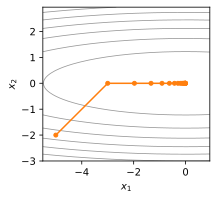

In [3]:
def adagrad_2d(x1, x2, s1, s2, f_grad, eta=2.0, eps=1e-6):
    g1, g2 = f_grad(x1, x2)
    s1, s2 = s1 + g1 ** 2, s2 + g2 ** 2
    x1 -= eta / math.sqrt(s1 + eps) * g1
    x2 -= eta / math.sqrt(s2 + eps) * g2
    return x1, x2, s1, s2

d2l.show_trace_2d(d2l.f_valley, d2l.train_2d(adagrad_2d, d2l.valley_grad))

Because $\mathbf{s}_t$ accumulates squared gradients monotonically without bound, AdaGrad's effective step size decays as $O(t^{-1/2})$ under persistent stochastic gradients, eventually halting progress on non-convex deep networks. **RMSProp** [@Tieleman.Hinton.2012] replaces the cumulative sum with an exponential moving average (EMA) $\mathbf{v}_t$ of squared gradients over a window of $\sim 1/(1-\beta_2)$ steps:

$$
\mathbf{v}_t = \beta_2\, \mathbf{v}_{t-1} + (1 - \beta_2)\, \mathbf{g}_t^2,
\qquad
\mathbf{x}_{t+1} = \mathbf{x}_t - \frac{\eta}{\sqrt{\mathbf{v}_t + \epsilon}} \odot \mathbf{g}_t.
$$

*(Note: following standard optimization notation, $\mathbf{v}_t$ here denotes the second-moment squared-gradient average rather than the velocity vector of that section.)* By forgetting ancient gradients, RMSProp maintains a non-vanishing step size even from a moderate learning rate $\eta = 0.4$:

step 20, x1: -0.010599, x2: 0.000000


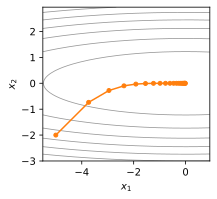

In [4]:
def rmsprop_2d(x1, x2, v1, v2, f_grad, eta=0.4, beta2=0.9, eps=1e-6):
    g1, g2 = f_grad(x1, x2)
    v1 = beta2 * v1 + (1 - beta2) * g1 ** 2
    v2 = beta2 * v2 + (1 - beta2) * g2 ** 2
    x1 -= eta / math.sqrt(v1 + eps) * g1
    x2 -= eta / math.sqrt(v2 + eps) * g2
    return x1, x2, v1, v2

d2l.show_trace_2d(d2l.f_valley, d2l.train_2d(rmsprop_2d, d2l.valley_grad))

Notice two properties of the equation:

1. **Early step amplification without bias correction:** Because $\mathbf{v}_0 = \mathbf{0}$, the first step has $\mathbf{v}_1 = (1 - \beta_2)\mathbf{g}_1^2$, causing an oversized initial jump of magnitude $\eta/\sqrt{1-\beta_2} \approx 3.16\,\eta$ at $\beta_2 = 0.9$ (and $31.6\,\eta$ at $\beta_2 = 0.999$).
2. **Normalized step length:** Whenever a coordinate's gradient has roughly steady magnitude, $\sqrt{v_t} \approx |g_t|$ and the update has magnitude $\approx \eta$ regardless of how small $|g_t|$ becomes. Near a minimum, a constant-rate adaptive method therefore oscillates within an $O(\eta)$ neighborhood until $\eta$ is decayed by a schedule (that section).

### Adam and Bias Correction

**Adam** [@Kingma.Ba.2014] combines an EMA of the first moment (momentum, $\mathbf{m}_t$) with an EMA of the uncentered second moment ($\mathbf{v}_t$), and applies exact **bias correction** to both estimators. Unrolling $\mathbf{v}_t = (1-\beta_2)\sum_{s=1}^t \beta_2^{t-s}\mathbf{g}_s^2$ from $\mathbf{v}_0 = \mathbf{0}$ shows that the weights sum to $1 - \beta_2^t$ rather than $1$. Dividing by $1 - \beta_1^t$ and $1 - \beta_2^t$ yields unbiased moment estimators $\hat{\mathbf{m}}_t$ and $\hat{\mathbf{v}}_t$:

$$
\begin{aligned}
\mathbf{m}_t &= \beta_1\, \mathbf{m}_{t-1} + (1 - \beta_1)\, \mathbf{g}_t,
\qquad &
\hat{\mathbf{m}}_t &= \frac{\mathbf{m}_t}{1 - \beta_1^t}, \\
\mathbf{v}_t &= \beta_2\, \mathbf{v}_{t-1} + (1 - \beta_2)\, \mathbf{g}_t^2,
\qquad &
\hat{\mathbf{v}}_t &= \frac{\mathbf{v}_t}{1 - \beta_2^t}.
\end{aligned}
$$

The parameter update divides the bias-corrected first moment by the coordinate RMS scale $\sqrt{\hat{\mathbf{v}}_t}$:

$$
\mathbf{x}_{t+1} = \mathbf{x}_t - \eta\, \frac{\hat{\mathbf{m}}_t}{\sqrt{\hat{\mathbf{v}}_t} + \epsilon}.
$$

Standard defaults are $\beta_1 = 0.9$, $\beta_2 = 0.999$ (or $\beta_2 = 0.95$ in large language model training [@brown2020language]), and $\epsilon = 10^{-8}$. At $t = 1$, $\hat{\mathbf{m}}_1 = \mathbf{g}_1$ and $\hat{\mathbf{v}}_1 = \mathbf{g}_1^2$, so the initial step is exactly $-\eta\,\operatorname{sign}(\mathbf{g}_1)$.

More generally, rescaling any coordinate of the objective by a positive constant $c > 0$ multiplies both $\hat{m}_{t,i}$ and $\sqrt{\hat{v}_{t,i}}$ by $c$, leaving their ratio invariant (for $\epsilon \to 0$). Thus, **under Adam, $\eta$ specifies a direct coordinate step length in parameter space**: a coordinate with consistent gradient sign moves by $\approx \eta$ per step, whereas a coordinate dominated by zero-mean noise moves by $\approx \eta\sqrt{(1-\beta_1)/(1+\beta_1)} \approx 0.23\,\eta$.

step 200, x1: 0.000022, x2: 0.000042


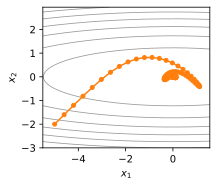

In [5]:
def adam_2d(x1, x2, s1, s2, f_grad, eta=0.4, beta1=0.9, beta2=0.999,
            eps=1e-8):
    def update(x, g, state):  # state: (m, v, t), 0 before the first step
        m, v, t = state if state else (0, 0, 0)
        m, v = beta1 * m + (1 - beta1) * g, beta2 * v + (1 - beta2) * g ** 2
        m_hat, v_hat = m / (1 - beta1 ** (t + 1)), v / (1 - beta2 ** (t + 1))
        return x - eta * m_hat / (math.sqrt(v_hat) + eps), (m, v, t + 1)
    g1, g2 = f_grad(x1, x2)
    (x1, s1), (x2, s2) = update(x1, g1, s1), update(x2, g2, s2)
    return x1, x2, s1, s2

path = d2l.train_2d(adam_2d, d2l.valley_grad, steps=200, beta2=0.999)
d2l.show_trace_2d(d2l.f_valley, path)

Implementing Adam from scratch requires maintaining the step counter $t$ and the two buffers $(\mathbf{m}, \mathbf{v})$ for each parameter tensor:

In [6]:
class Adam(torch.optim.Optimizer):
    """Adam from scratch: steps scaled by two debiased moving averages."""
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            (beta1, beta2), lr, eps = group['betas'], group['lr'], group['eps']
            for p in group['params']:
                if p.grad is None:  # A parameter that received no gradient
                    continue
                state = self.state[p]
                if not state:  # First step: t = 0 and m = v = 0
                    state.update(t=0, m=torch.zeros_like(p),
                                 v=torch.zeros_like(p))
                state['t'] += 1
                t, m, v = state['t'], state['m'], state['v']
                m.mul_(beta1).add_(p.grad, alpha=1 - beta1)
                v.mul_(beta2).add_(p.grad ** 2, alpha=1 - beta2)
                m_hat, v_hat = m / (1 - beta1 ** t), v / (1 - beta2 ** t)
                p.sub_(lr * m_hat / (v_hat.sqrt() + eps))

## Adam on a Language Model

### Gradient Scales and Comparison with SGD on `TinyLM`

Why is per-coordinate scaling so critical for Transformers? To measure gradient scales across `TinyLM` (that section), we first load the `WikiText103` dataset ($b = 64$, window length $64$):

In [7]:
data = d2l.WikiText103(batch_size=64, num_steps=64)

Next we define `gradients(model, data)` to compute the root-mean-square (RMS) gradient of each parameter tensor over $10$ minibatches, `snapshot(model)` to clone parameter values, and an initial `TinyLM` instance with Adam ($\eta = 3 \times 10^{-3}$):

In [8]:
def gradients(model, data, num_batches=10):
    """RMS over num_batches minibatches of each parameter's gradient."""
    device = d2l.try_gpu()
    sq = {name: 0 for name, _ in model.named_parameters()}
    for _, (X, Y) in zip(range(num_batches), data.train_dataloader()):
        model.zero_grad()
        loss = F.cross_entropy(model(X.to(device)).flatten(0, 1),
                               Y.to(device).flatten())
        loss.backward()
        for name, p in model.named_parameters():
            sq[name] += p.grad ** 2 / num_batches
    return {name: v.sqrt() for name, v in sq.items()}

def snapshot(model):
    return {name: p.detach().clone() for name, p in model.named_parameters()}

model = d2l.TinyLM(len(data.vocab)).to(d2l.try_gpu())
optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)

Grouping tensors into the $8$ functional parameter kinds via `rms_by_kind`, we compare their RMS gradient magnitudes at step $0$ and step $500$ alongside the normalized Adam step length $\|\Delta\mathbf{x}\|_{\text{RMS}} / \eta$:

In [9]:
KINDS = ['token_emb', 'pos_emb', 'qkv', 'proj', 'mlp', 'head']

def rms_by_kind(tensors):
    """RMS of the entries of each kind of parameter, from {name: tensor}."""
    sums, counts = {}, {}
    for name, t in tensors.items():
        kind = (('LayerNorm' if 'norm' in name else 'biases')
                if len(t.shape) == 1 else
                next(k for k in KINDS if k in name))
        sums[kind] = sums.get(kind, 0) + float((t ** 2).sum())
        counts[kind] = counts.get(kind, 0) + math.prod(t.shape)
    return {kind: math.sqrt(sums[kind] / counts[kind]) for kind in sums}

grad_init = rms_by_kind(gradients(model, data))
d2l.train_steps(model, data, optimizer, num_steps=500)
grad_500 = rms_by_kind(gradients(model, data))
before = snapshot(model)
d2l.train_steps(model, data, optimizer, num_steps=1)
after = snapshot(model)
step = rms_by_kind({name: (before[name] - after[name]) / 3e-3
                    for name in before})
print(f'{"":<11}{"RMS gradient at step 0":>24}{"at step 500":>13}'
      f'{"Adam step / lr":>16}')
for kind in KINDS + ['LayerNorm', 'biases']:
    print(f'{kind:<11}{grad_init[kind]:>24.1e}{grad_500[kind]:>13.1e}'
          f'{step[kind]:>16.2f}')
ratio = lambda column: max(column.values()) / min(column.values())
print(f'{"max / min":<11}{ratio(grad_init):>24.0f}{ratio(grad_500):>13.0f}'
      f'{ratio(step):>16.1f}')

             RMS gradient at step 0  at step 500  Adam step / lr
token_emb                   1.9e-04      9.8e-05            0.21
pos_emb                     1.7e-04      1.7e-04            0.28
qkv                         8.0e-04      3.8e-04            0.25
proj                        1.5e-03      5.5e-04            0.21
mlp                         9.8e-04      2.6e-04            0.24
head                        4.5e-03      1.5e-03            0.12
LayerNorm                   4.7e-03      1.4e-03            0.20
biases                      6.9e-03      6.7e-04            0.17
max / min                        40           15             2.3


Raw gradient magnitudes span a **$40\times$ range** at initialization (from $\sim 2 \times 10^{-4}$ on token embeddings to $\sim 7 \times 10^{-3}$ on biases) and a **$15\times$ range** at step $500$. Under SGD, a single scalar learning rate moves the groups with the largest gradients (biases, LayerNorm, the output head) $15\text{--}40\times$ faster than the embeddings; under Adam, the normalized step size across all eight parameter groups lies within a narrow $2\times$ band ($0.1\eta\text{--}0.3\eta$, close to the pure-noise ratio $\sqrt{(1-\beta_1)/(1+\beta_1)} \approx 0.23$).

Because gradient scales in `TinyLM` lie around $10^{-4}\text{--}10^{-2}$ and Adam's EMA includes $(1-\beta_1) = 0.1$, Adam at $\eta \sim 3 \times 10^{-3}$ produces parameter steps comparable in magnitude to SGD with momentum $0.9$ at $\eta \sim 0.3$. To compare both optimizers across $3$ shared seeds, we first set up the model and optimizer closures `make_lm`, `make_sgd`, and `make_adam`:

In [10]:
make_lm = lambda: d2l.TinyLM(len(data.vocab))
make_sgd = lambda model, lr: torch.optim.SGD(model.parameters(), lr,
                                             momentum=0.9)
make_adam = lambda model, lr: torch.optim.Adam(model.parameters(), lr)
seeds = [random.getrandbits(31) for _ in range(3)]

We then sweep SGD with momentum across $\eta \in \{0.1, 0.3, 0.5, 1.0\}$ and Adam across $\eta \in \{3 \times 10^{-4}, 10^{-3}, 3 \times 10^{-3}, 10^{-2}, 3 \times 10^{-2}\}$ from identical initial weights per seed:

In [11]:
def sweep(make_optimizer, lrs):
    """Loss curves of one run per learning rate and seed, printing the final
    losses; the runs of one seed start from the same initialization."""
    runs = [d2l.lr_sweep(make_lm, make_optimizer, data, lrs, seed,
                         verbose=False)[0] for seed in seeds]
    for lr in lrs:
        print(f'  lr {lr:<7g}', *(f'{d2l.final_loss(run[lr]):6.3f}'
                                  for run in runs))
    return {lr: [run[lr] for run in runs] for lr in lrs}

print('final loss of three runs, SGD with momentum')
sgd_lm = sweep(make_sgd, [0.1, 0.3, 0.5, 1.0])
print('Adam')
adam_lm = sweep(make_adam, [3e-4, 1e-3, 3e-3, 1e-2, 3e-2])

final loss of three runs, SGD with momentum


  lr 0.1      1.855  1.858  1.881
  lr 0.3      1.650  1.652    inf
  lr 0.5        inf    inf    inf
  lr 1          inf    inf    inf
Adam


  lr 0.0003   1.931  1.929  1.946
  lr 0.001    1.690  1.668  1.660
  lr 0.003    1.583  1.592  1.587
  lr 0.01     1.641  1.646  1.648
  lr 0.03     2.811  2.784  2.811


Summarizing each optimizer at its best learning rate (`best_rate`), we compare the usable learning-rate range (within $0.15$ nats of the optimum), steps to reach $1.8$ nats, maximum single-step loss spikes, and smoothed loss trajectories:

In [ ]:
def best_rate(curves):
    """The lr with the lowest mean final loss, and each lr's mean."""
    mean = {lr: sum(map(d2l.final_loss, runs)) / len(runs)
            for lr, runs in curves.items()}
    return min(mean, key=mean.get), mean

print(f'{"":6}{"best lr":>8}{"final loss":>17}   {"within 0.15 nats":<18}'
      f'{"steps to 1.8":<16}largest one-step rise')
for name, curves in [('SGD', sgd_lm), ('Adam', adam_lm)]:
    best, mean = best_rate(curves)
    runs = curves[best]
    finals = [d2l.final_loss(run) for run in runs]
    usable = [f'{lr:g}' for lr in curves if mean[lr] <= mean[best] + 0.15]
    steps = ' '.join(str(d2l.steps_to_reach(run, 1.8)) for run in runs)
    rises = ' '.join(f'{max(b - a for a, b in zip(run, run[1:])):.2f}'
                     for run in runs)
    print(f'{name:<6}{best:>8g}{min(finals):>8.3f} to {max(finals):.3f}   '
          f'{" ".join(usable):<18}{steps:<16}{rises}')
best_sgd, best_adam = best_rate(sgd_lm)[0], best_rate(adam_lm)[0]
d2l.plot(list(range(0, 2000, 25)),
         [d2l.smooth(sgd_lm[best_sgd][0]),
          d2l.smooth(adam_lm[best_adam][0])],
         'step', 'training loss',
         legend=[f'SGD + momentum, lr {best_sgd:g}',
                 f'Adam, lr {best_adam:g}'])

On `TinyLM`, Adam reaches a target loss of $1.8$ nats in nearly half the steps of SGD with momentum ($650\text{--}800$ vs. $1{,}100\text{--}1{,}500$), finishes at a lower final loss, operates across a $10\times$ usable learning-rate window ($10^{-3}$ to $10^{-2}$), and remains finite even at $\eta = 3 \times 10^{-2}$ because its normalized update length is bounded by $\eta$. SGD's best rate, $\eta = 0.3$, sits one grid step below divergence: its worst one-step loss spikes are several times Adam's, and at $\eta = 0.5$ most runs diverge to `inf`. On larger Transformers with subword vocabularies, this gap widens further due to block-level Hessian heterogeneity [@Zhang.Chen.Ding.ea.2024] and heavy-tailed token frequencies [@Kunstner.Chen.Lavington.ea.2023; @Kunstner.Yadav.Milligan.ea.2024].

In this run, one spike sets an SGD seed back so far that it never reaches $1.8$.

### Role of $\epsilon$ and Limits of the Second-Moment Estimate

In the equation, $\epsilon$ caps the maximum effective coordinate learning rate at $\eta / \epsilon$; in the limit $\epsilon \gg \sqrt{\hat{v}_{t,i}}$, Adam reduces to SGD with momentum at step size $(1-\beta_1)\eta/\epsilon$. Conversely, when $\beta_2$ is too small, a short-memory second-moment estimate can weight frequent small gradients more heavily than occasional large opposing gradients—a phenomenon used by @Reddi.Kale.Kumar.2019 to construct a synthetic periodic convex counterexample ($+4, -1, -1$) on which small-$\beta_2$ Adam fails to converge (that section; Exercise 4). In practice, keeping $\beta_2 \in [0.95, 0.999]$ prevents this pathology without requiring monotonic running maxima (AMSGrad).

## Decoupled Weight Decay (AdamW)

### Coupled $\ell_2$ Regularization vs. Decoupled Weight Decay

Under plain SGD (that section), adding an $\ell_2$ penalty $\frac{\lambda}{2}\|\mathbf{x}\|^2$ to the objective adds $\lambda\mathbf{x}_t$ to the gradient, which is mathematically identical to shrinking the weights by $(1 - \eta\lambda)$ before each step:

$$
\mathbf{x}_{t+1} = \mathbf{x}_t - \eta\,(\mathbf{g}_t + \lambda \mathbf{x}_t)
= (1 - \eta\lambda)\,\mathbf{x}_t - \eta\,\mathbf{g}_t.
$$

When the penalized gradient $\mathbf{g}_t + \lambda\mathbf{x}_t$ is fed into Adam, however, the penalty term is divided by the coordinate preconditioner $\sqrt{\hat{v}_{t,i}} + \epsilon$:

$$
\underbrace{\frac{\eta\,\lambda}{\sqrt{\hat{v}_{t,i}} + \epsilon}\; x_{t,i}}_{\textrm{coupled $\ell_2$ penalty in Adam}}
\qquad \textrm{versus} \qquad
\underbrace{\eta\,\lambda\; x_{t,i}\vphantom{\frac{\eta}{\sqrt{\hat{v}_{t,i}}}}}_{\textrm{decoupled weight decay}}.
$$

Under coupled $\ell_2$ regularization, weights with small loss gradients are decayed up to $10^3\times$ more aggressively than weights with large gradients—or, when $\lambda|x_{t,i}|$ dominates the loss gradient, Adam normalizes the penalty by its own magnitude and drives the weight toward zero at speed $\eta$ per step until $\lambda|x| \sim |g_{\text{loss}}|$.

@Loshchilov.Hutter.2019 introduced **AdamW**, which decouples weight decay from the adaptive gradient step:

$$
\mathbf{x}_{t+1} = (1 - \eta\lambda)\,\mathbf{x}_t
- \eta\, \frac{\hat{\mathbf{m}}_t}{\sqrt{\hat{\mathbf{v}}_t} + \epsilon},
$$

where $\hat{\mathbf{m}}_t$ and $\hat{\mathbf{v}}_t$ are computed solely from the data loss gradient $\mathbf{g}_t$.

In [13]:
class AdamW(torch.optim.Adam):
    """Adam with decoupled weight decay: shrink the weights, then step."""
    def __init__(self, params, lr=1e-3, weight_decay=0.01):
        super().__init__(params, lr)  # Adam's own weight_decay stays 0
        self.weight_decay = weight_decay

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            for p in group['params']:
                if p.grad is not None:
                    p.mul_(1 - group['lr'] * self.weight_decay)
        super().step()

To compare no decay, coupled `Adam + l2`, and decoupled `AdamW` on `TinyLM`, we first define `matrix_rms` to measure the entrywise RMS of the 2D non-embedding weight matrices and `train_tracked` to record both the step losses and the matrix RMS every $250$ steps:

In [14]:
def matrix_rms(model):
    """RMS of the entries of the weight matrices, embeddings excluded."""
    W = torch.cat([p.detach().flatten() for name, p in model.named_parameters()
                   if p.ndim == 2 and 'emb' not in name])
    return float(W.square().mean().sqrt())

def train_tracked(make_optimizer, data, seed, num_steps, every=250):
    """Train TinyLM from seed with make_optimizer(params); return the losses,
    the matrix RMS at the start and every `every` steps, and the model."""
    torch.manual_seed(seed)
    model = d2l.TinyLM(len(data.vocab))
    optimizer = make_optimizer(model.parameters())
    losses, rms = [], [matrix_rms(model)]
    for _ in range(num_steps // every):
        losses += d2l.train_steps(model, data, optimizer, every)
        rms.append(matrix_rms(model))
    return losses, rms, model

Running all three configurations for $1{,}000$ steps at $\eta = 3 \times 10^{-3}$ and $\lambda = 0.1$ from a shared seed shows the dramatic difference between coupled $\ell_2$ penalty and decoupled weight decay:

no decay   final loss 1.700, RMS of the weight matrices 0.0447 -> 0.1101


Adam + ℓ2  final loss 3.192, RMS of the weight matrices 0.0447 -> 0.0026


AdamW      final loss 1.703, RMS of the weight matrices 0.0447 -> 0.0986


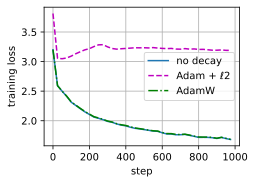

In [15]:
seed = random.getrandbits(31)
curves = {}
for name, make_optimizer in [
        ('no decay', lambda params: torch.optim.Adam(params, 3e-3)),
        ('Adam + ℓ2', lambda params: torch.optim.Adam(params, 3e-3,
                                                       weight_decay=0.1)),
        ('AdamW', lambda params: torch.optim.AdamW(params, 3e-3,
                                                    weight_decay=0.1))]:
    curves[name], rms, _ = train_tracked(make_optimizer, data, seed, 1000)
    print(f'{name:<10} final loss {d2l.final_loss(curves[name]):.3f}, RMS of '
          f'the weight matrices {rms[0]:.4f} -> {rms[-1]:.4f}')
d2l.plot(list(range(0, 1000, 25)), [d2l.smooth(c) for c in curves.values()],
         'step', 'training loss', legend=list(curves))

Coupled `Adam + l2` at $\lambda = 0.1$ collapses the hidden weight matrices from an initial RMS of $0.045$ down to $< 0.003$, destroying the network's representation and stalling at the unigram byte-frequency entropy ($\sim 3.2$ nats/byte). Decoupled `AdamW` trains cleanly alongside the unregularized baseline while bounding weight growth.

### The Timescale of Decay and Equilibrium Norm

Writing $\mathbf{u}_t = \hat{\mathbf{m}}_t / (\sqrt{\hat{\mathbf{v}}_t} + \epsilon)$ for Adam's normalized update direction and unrolling the equation over $t$ steps yields

$$
\mathbf{x}_t = (1 - \eta\lambda)^t\, \mathbf{x}_0
- \eta \sum_{s=0}^{t-1} (1 - \eta\lambda)^{t-1-s}\, \mathbf{u}_s.
$$

Thus, AdamW expresses the parameters $\mathbf{x}_t$ as an exponentially weighted moving average of past updates with decay factor $1 - \eta\lambda \approx e^{-\eta\lambda}$ and characteristic **decay timescale**

$$\tau = \frac{1}{\eta\lambda}$$

steps [@Wang.Aitchison.2025]. At $\eta = 3 \times 10^{-3}$ and $\lambda = 0.1$, the decay timescale is $\tau = 1 / 0.0003 \approx 3{,}333$ steps. Over a $T$-step run, weight decay acts across $T / \tau = T\eta\lambda$ timescales.

Over runs longer than $\tau = 1/(\eta\lambda)$, the initial weights decay away and each coordinate $x_{t,i}$ reaches a stochastic **equilibrium norm** where per-step shrinkage $\eta\lambda x_{t,i}$ balances the injection of normalized updates $-\eta n_{t,i}$ (with $n_{t,i} = g_{t,i}/\sqrt{\hat{v}_{t,i}}$ of unit mean square $\sigma^2 \approx 1$). By the exact same variance recursion as the SGD noise ball (that section) with $\lambda_{\text{decay}}$ in place of curvature:

$$
\begin{aligned}
\mathbb{E}\big[x_{t+1}^2\big] &= (1 - \eta\lambda)^2\, \mathbb{E}\big[x_t^2\big] + \eta^2 \sigma^2 \\
\Longrightarrow \quad \mathbb{E}\big[x_\infty^2\big] &\approx \frac{\eta\, \sigma^2}{2\lambda} \approx \frac{\eta}{2\lambda}.
\end{aligned}
$$

Stabilizing the root-mean-square weight magnitude at $\text{RMS}(\mathbf{x}_\infty) \propto \sqrt{\eta / (2\lambda)}$ stabilizes the **relative angular update rate** of normalized weight matrices at $\eta / \text{RMS}(\mathbf{x}_\infty) \propto \sqrt{2\eta\lambda}$ (*rotational equilibrium*, @Kosson.Messmer.Jaggi.2024), preventing the uncontrolled $\sqrt{t}$ random-walk growth of unregularized weights that would otherwise decay the effective angular step size as $1/\sqrt{t}$ over long pretraining runs [@DAngelo.Andriushchenko.Varre.ea.2024]. When sweeping $\eta$, holding the per-step shrinkage $s = \eta\lambda$ (and thus the timescale $\tau = 1/s$) fixed decouples the learning-rate search from the decay timescale [@Loshchilov.Hutter.2019; @Wang.Aitchison.2025; @Bergsma.Dey.Gosal.ea.2025b].

### Parameters Exempt from Weight Decay and Optimizer State Memory

Standard Transformer recipes apply decoupled weight decay to the weight matrices and exempt biases and normalization parameters. OLMo 2 additionally exempts the embedding tables, and we adopt that choice here. Decay is then applied **only to 2D internal projection matrices** ($90\%$ of `TinyLM`), while two parameter groups are exempted ($\lambda = 0$):

1. **1D biases and LayerNorm/RMSNorm gain and shift vectors:** Normalization scales start near $1$ and directly control feature variance; decaying them toward zero distorts layer activations rather than regulating angular update speed.
2. **Token and positional embedding tables (the OLMo 2 exemption):** Token embedding rows receive gradients only when their token appears in a minibatch, whereas decoupled decay shrinks every row on every step, collapsing rare token representations and inflating downstream LayerNorm gradients [@OLMo.2025].

In [16]:
model = d2l.TinyLM(len(data.vocab))
decay = [p for name, p in model.named_parameters()
         if p.ndim == 2 and 'emb' not in name]
no_decay = [p for name, p in model.named_parameters()
            if p.ndim != 2 or 'emb' in name]
optimizer = torch.optim.AdamW([
    {'params': decay, 'weight_decay': 0.1},
    {'params': no_decay, 'weight_decay': 0.0}], lr=3e-3)
n_decay = sum(p.numel() for p in decay)
n = n_decay + sum(p.numel() for p in no_decay)
print(f'decayed: {n_decay} of {n} parameters')

decayed: 425984 of 470784 parameters


### Optimizer State Memory

Finally, maintaining the two per-parameter buffers $(\mathbf{m}_t, \mathbf{v}_t)$ doubles the static parameter memory footprint. In 32-bit floating point ($4$ bytes per scalar), each trainable parameter requires **$16$ bytes** of device memory: $4$ bytes for the parameter $\mathbf{x}$, $4$ bytes for the gradient $\mathbf{g}$, and $8$ bytes for the AdamW state $(\mathbf{m}, \mathbf{v})$ (that section). For a $10^9$-parameter model, the optimizer state alone consumes $8\text{ GB}$ before storing any activations. Freezing parameters (leaving them out of the optimizer) or quantizing/factoring $(\mathbf{m}, \mathbf{v})$ directly eliminates or compresses this $8$-byte-per-parameter overhead.

While AdamW normalizes each weight entry independently, 2D weight matrices act as linear operators on activation vectors. that section asks whether we can do even better by normalizing the update of each 2D weight matrix as a whole operator rather than entry by entry.

## Summary

**AdaGrad** scales each coordinate inversely by the root of its cumulative squared gradients, **RMSProp** replaces that unbounded sum with a leaky exponential moving average $\mathbf{v}_t$, and **Adam** adds first-moment momentum $\mathbf{m}_t$ together with bias corrections $1 - \beta_1^t$ and $1 - \beta_2^t$. Dividing $\hat{\mathbf{m}}_t$ by $\sqrt{\hat{\mathbf{v}}_t}$ makes Adam invariant to diagonal rescaling of the gradient, turning $\eta$ into a direct coordinate step length in parameter space and equalizing update magnitudes across Transformer parameter groups whose raw gradients differ by $15\text{--}40\times$. **AdamW** decouples weight decay $\mathbf{x}_{t+1} = (1 - \eta\lambda)\mathbf{x}_t - \eta\hat{\mathbf{m}}_t/(\sqrt{\hat{\mathbf{v}}_t}+\epsilon)$ from the adaptive preconditioner, establishing a uniform decay timescale $\tau = 1/(\eta\lambda)$, an equilibrium weight RMS proportional to $\sqrt{\eta/(2\lambda)}$, and a steady relative angular step proportional to $\sqrt{2\eta\lambda}$. Standard recipes decay only 2D weight matrices while exempting 1D biases and normalization parameters (and, following OLMo 2, embedding tables), with $(\mathbf{m}_t, \mathbf{v}_t)$ accounting for $8$ of the $16$ bytes per trainable parameter in `float32`.

## Exercises

1. [code] **Coordinate rotation vs. diagonal scale invariance.**
    1. Verify with `adam_2d` on `d2l.f_valley` that Adam is invariant to rescaling the objective by $c > 0$ (for $c \gg \epsilon$) and to changing $\lambda_2$ from $4$ to $400$.
    1. Rotate the valley by $45^\circ$ via $f(\mathbf{x}) = 0.05(x_1 + x_2)^2 + (x_1 - x_2)^2$. Run `adagrad_2d`, `rmsprop_2d`, and `adam_2d` at $\eta = 0.4$ for $2{,}000$ steps on the unrotated and rotated valleys (and with $\lambda_2 = 400$), and explain why rotating the eigenbasis away from the coordinate axes restores ill-conditioning for diagonal preconditioners.

1. [code] **Constant-rate limit cycles and AMSGrad.** ●
    1. Show that if a 1D coordinate alternates as $x_t = (-1)^t a$ on $f(x) = \frac{\lambda}{2}x^2$ under Adam, its amplitude is $a = \frac{1-\beta_1}{1+\beta_1}\frac{\eta}{2}$ independent of $\lambda$.
    1. Run `adam_2d` on `f_valley` for $20{,}000$ steps and explain why the iterate approaches within $10^{-40}$ of the origin while $\hat{v}_t$ remembers the initial gradients, then gets ejected once $\hat{v}_t$ decays below the momentum stability threshold. Verify that replacing $\hat{v}_t$ with $\max_{s \le t} \hat{v}_s$ (AMSGrad) prevents the ejection.

1. [extended] **Frequent and rare tokens and per-group learning rates.**
    1. Following @Kunstner.Yadav.Milligan.ea.2024, partition the $256$ byte values of `WikiText103` into frequent ($\ge 0.1\%$) and rare ($< 0.1\%$) tokens, and compare validation loss on each group under tuned SGD with momentum, Adam, and sign descent with momentum ($\eta\,\operatorname{sign}(\mathbf{m}_t)$).
    1. Assign separate learning rates to the three parameter groups of `TinyLM` (embeddings, 2D matrices, 1D vectors) under SGD with momentum, and measure how much of the SGD–Adam gap is closed by group-level versus coordinate-level scaling.

1. [code] **Adversarial periodic gradients and second-moment repairs.** On the 3-periodic sequence $f_t(x) = 4x$ ($t \equiv 1 \pmod 3$) and $f_t(x) = -x$ otherwise on $x \in [-1, 1]$ [@Reddi.Kale.Kumar.2019], run Adam with $\beta_1 = 0, \beta_2 = 1/17, \eta_t = 0.5/\sqrt{t}$ and compare it against AMSGrad and Yogi [@Zaheer.Reddi.Sachan.ea.2018].

1. **Two limits of AdamW and rotational equilibrium.**
    1. For $x_{t+1} = (1 - \eta\lambda)x_t - \eta n_t$, derive the deterministic equilibrium $|x_\infty| = 1/\lambda$ when $n_t = -1$ is constant, the zero-mean noise equilibrium $\mathbb{E}[x_\infty^2] \approx \eta/(2\lambda)$ when $n_t$ is i.i.d. with $\mathbb{E}[n_t]=0, \mathbb{E}[n_t^2]=1$, and the mixed equilibrium $\mathbb{E}[x_\infty^2] \approx \bar{n}^2/\lambda^2 + \eta/(2\lambda)$ when $n_t = \bar{n} + \xi_t$.
    1. Simulate $\mathbf{x}_{t+1} = (1 - \eta\lambda)\mathbf{x}_t - \eta\mathbf{u}_t$ in $\mathbb{R}^{1000}$ with $\mathbf{u}_t \perp \mathbf{x}_t$ [@Kosson.Messmer.Jaggi.2024] to verify that the equilibrium RMS matches $\sqrt{\eta/(2\lambda)}$ and the per-step rotation angle matches $\sqrt{2\eta\lambda}$.

1. [code] **Joint $(\eta, \lambda)$ search and parameter-group exemptions.** ●
    1. Train `TinyLM` on $8{,}000$ overlapping windows of `d2l.TimeMachine` for $800$ steps across a grid of $\eta \in \{10^{-3}, 3 \times 10^{-3}, 10^{-2}\}$ and $\lambda$, comparing parametrization by $\lambda$ versus per-step shrinkage $s = \eta\lambda$.
    1. Compare validation perplexity on `WikiText103` at $\lambda \in \{0.5, 1.0\}$ when decaying all parameters versus decaying only 2D weight matrices (that section), and identify whether exempting embeddings or 1D vectors accounts for most of the gain.

[Discussions](https://d2l.discourse.group/t/1078)